# **Laboratory I**

**Students:**
**Mălina-Teodora Dumitrescu, 7729845**
**Niloofar Amiri, 7513798**

**Github Repository: https://github.com/MalinaDumitrescu/advanced-medical-informatics/blob/main/labor_1.ipynb**

## **Problem 1**

a) **Data integration** means combining information from different sources into one dataset. This can improve data quality , reduce missing or duplicate information and help identify patterns that may not be visible when looking at each dataset separately.

**Example:** combining clinical records with genetic data -> this could help us make a better treatment plan for the patient.

A **Confounder** is a variable that is related to both the predictor and the outcome. It can distort the relationship between them and lead to misleading conclusions.

**Example:** age can be a confounder when studying the relationship between physical; activity and heart diseases, because it may influence both.

b) **Regression and classification** are both supervised learning methods.

**Regression** is used to predict numerical values **(ex. blood pressure, salary etc.)**. The model learns the relationship between the input variables and a continuous output variable.

**Classification** is used to predict categorical values **(ex. email = spam/not spam, patient has/does not have disease)** .

c) A **Confidence Interval** is a range of values used to estimate an unknown population param. It also shows how precise our estimate is.

**Example:** a 95% confidence interval means that if we repeated the sampling process many times, about 95% of the intervals calculated in this way would contain the true population param.

d) **Difference between multiclass classification and binary classification** - both models predict categorical values, but the number of classes differs.

**Binary Classification** divides observations into two possible classes.

**Example:** a medical test could classify a patient as either positive-(1) or negative-(2) for a disease.

**Multiclass Classification** has more than two possible classes.

**Example:** a model could classify a medical image into one of several different disease categories.

e) The **p-value** is the probability of obtaining a test result at least as extreme as the one observed one, assuming that the null hypothesis is true. A small p-value indicates that the observed result would be unlikely under the null hypothesis, therefore providing evidence against it.

f) The **significance level $\alpha$** is the maximum probability of making a Type I error, which means rejecting the null hypothesis even thought it's true.

$$
P(\text{reject }H_0 \mid H_0\text{ is true}) \leq \alpha
$$

For a test with an exact type I error probability of $\alpha$, this becomes an equality. A common used significance level is $\alpha$ = 0.05, meaning that we accept a max. 5% probability of incorrectly rejecting a true null hypothesis.

## **Problem 2**

![Advertising results](table_ex_2.jpeg)

- in the table we have the results of a multiple linear regression model:
- the response variable is sales;
- the predictors are the TV, radio and newspaper advertising spendings;
-  $\alpha = 0.05$ as significance level.

**Intercept (p-value < 0.0001)**

The null hypothesis is that expected sales are zero when no money is spent on TV, radio, or newspaper advertising.

Since the p-value is below 0.05, we reject the null hypothesis => indicates that the model predicts nonzero sales even without advertising spending.

**TV advertising (p-value < 0.0001)**

The null hypothesis is that TV advertising spending has no linear relationship with sales when radio and newspaper advertising spending are held constant.

Since the p-value is below 0.05, we reject the null hypothesis. There
is strong statistical evidence of a positive relationship between TV advertising spending and sales, after accounting for the other two advertising channels.

**Radio advertising (p-value < 0.0001)**

The null hypothesis is that radio advertising spending has no linear relationship with sales when TV and newspaper advertising spending are held constant.

Since the p-value is also below 0.05, we reject the null hypothesis. Radio advertising spending has a statistically significant positive relationship with sales, after accounting for TV and newspaper advertising.

**Newspaper advertising (p-value = 0.8599)**

The null hypothesis is that newspaper advertising spending has no linear relationship with sales when TV and radio advertising spending are held constant.

Since the p-value is much larger than 0.05, we fail to reject the null hypothesis. This means that there is not enough statistical evidence of a relationship between newspaper advertising spending and sales after accounting for the other advertising channels.

However, this does not prove that newspaper advertising has no effect. It only means that we cannot establish a statistically significant relationship based on this model.

**Conclusion**

Based on the regression results, TV and radio advertising spending have statistically significant positive relationships with sales, while newspaper advertising spending does not show a statistically significant additional relationship when the other channels are taken into account.

## **Problem 3**

**K-Nearest Neighbors (KNN)** is a supervised learning method that can be used for both classification and regression. The basic idea is that observations with similar characteristics often have similar outcomes.

When we want to make a prediction for a new observation, KNN looks for the (k) closest observations in the training dataset. The distance is usually calculated using Euclidean distance, although other distance measures, such as Manhattan distance, can also be used.

For two observations (x) and (z), with (p) features, the Euclidean distance is:

$
d(x,z)=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}
$

After calculating the distances, the algorithm selects the (k) nearest neighbors and uses their known outcomes to make a prediction.

**KNN Classification**

In KNN classification, the predicted class is the one that appears most frequently among the (k) nearest neighbors.

For example, suppose we want to predict whether a patient has a certain disease. If we choose (k=5), the algorithm finds the five most similar patients in the training dataset. If three of them have the disease and two do not, the new patient will be classified as having the disease.

The predicted class can be written as:

$
\hat{y}(x)=\underset{c}{\arg\max}
\sum_{i\in N_k(x)} I(y_i=c)
$

where $N_k(x)$ contains the indices of the (k) nearest neighbors and $I(y_i=c)$ is 1 if observation (i) belongs to class (c), and 0 otherwise.

**KNN Regression**

KNN regression follows the same steps, but instead of predicting a class, it predicts a numerical value.

After finding the (k) nearest neighbors, the algorithm calculates the average of their output values:

$
\hat{y}(x)=\frac{1}{k}\sum_{i\in N_k(x)}y_i
$

For example, if we want to predict a patient's blood pressure using (k=3), and the three nearest patients have blood pressures of 120, 125, and 130 mmHg, the prediction would be:

$
\hat{y}(x)=\frac{120+125+130}{3}=125\text{ mmHg}
$

**Choosing (k)**

The value of (k) is important because it affects the predictions.

If (k) is too small, the model can be very sensitive to noise and individual observations, which can lead to overfitting. If (k) is too large, the model may include neighbors that are not very similar, which can lead to underfitting.

The value of (k) can be selected using cross-validation.

Another important point is feature scaling. Since KNN uses distances, features with larger numerical ranges can have a stronger influence on the result. Therefore, it is often useful to standardize the features before applying KNN.

## **TL;dr:**

Both approaches use the same method to find neighbors. The difference is how they make the final prediction: KNN classification uses the majority class, while KNN regression uses the average of the neighbors' numerical values.

In [1]:
# TODO (NOT A TODO, but good for highlighting stuff :) the code is only for us to refresh our memory,so it's not relevant for the assigment. Though, it looks tidy and nice, so we decided to keep it here. Sorry for the length of the solutions...and thanks!!!

import  numpy as np
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

# we choose k=3

# age and blood pressure of five patients
X = np.array([[25, 120], [30, 130], [35, 140], [40, 150], [45, 160]])
# no disease = 0, disease = 1
y = np.array([0, 0, 1, 1, 1])
patient = np.array([[48, 145]])

# KNN Classification
knn_classification = KNeighborsClassifier(n_neighbors=3)
knn_classification.fit(X,y)
prediction = knn_classification.predict(patient)
print("Predicted class: ", prediction[0])

#****************************************************

# KNN Regression
y_reg = np.array([120, 130, 140, 150, 160])

knn_regression = KNeighborsRegressor(n_neighbors=3)
knn_regression.fit(X, y_reg)
prediction = knn_regression.predict(patient)
print("Predicted value: ", prediction[0])

Predicted class:  1
Predicted value:  150.0


## **Problem 4**

We have a linear regression model that predicts starting salary in thousands of euros.

![ex_4.png](ex_4.png)

The estimated regression model is:

$
\hat{Y}=\hat{\beta}_0+\hat{\beta}_1X_1+\hat{\beta}_2X_2+\hat{\beta}_3X_3+\hat{\beta}_4X_4+\hat{\beta}_5X_5
$

After inserting the given values:

$
\hat{Y}=50+20GPA+0.07IQ+35Gender+0.01(GPA\cdot IQ)-10(GPA\cdot Gender)
$

a) To determine which statement is correct, we need to compare the predicted salaries for males and females with the same GPA and IQ.

For males**Gender=0**, the model becomes:

$
\hat{Y}_{male}=50+20GPA+0.07IQ+0.01(GPA\cdot IQ)
$

For females **Gender=1**:

$
\hat{Y}_{female}=50+20GPA+0.07IQ+35+0.01(GPA\cdot IQ)-10GPA
$

We can now subtract the male salary from the female salary:

$
\hat{Y}{female}-\hat{Y}{male}=35-10GPA
$

This means that the difference in predicted salary depends on GPA.

To find the GPA at which both genders have the same predicted salary, we set the difference equal to zero:

$
35-10GPA=0
$

$
GPA=\frac{35}{10}=3.5
$

Therefore:

If GPA < 3.5, the difference is positive, so females have a higher predicted salary.

If GPA = 3.5, both genders have the same predicted salary.

If GPA>3.5, the difference is negative, so males have a higher predicted salary.

**The correct answer is (iii)**: For a fixed value of IQ and GPA, males earn more on average than females provided that the GPA is high enough. This happens when GPA is greater than 3.5.

(b) Predict the salary of a female with IQ of 110 and GPA of 4.0.

We have:
$
GPA=4.0,\qquad IQ=110,\qquad Gender=1
$

First, we calculate the interaction terms:

$
X_4=GPA\cdot IQ=4.0\cdot110=440
$

$
X_5=GPA\cdot Gender=4.0\cdot1=4
$

Now we substitute these values into the regression equation:

$
\hat{Y}=50+20(4.0)+0.07(110)+35(1)+0.01(440)-10(4)
$

$
\hat{Y}=50+80+7.7+35+4.4-40
$

$
\hat{Y}=137.1
$

Since salary is measured in thousands of euros, the predicted starting salary is:

$
137.1\times1000=137,100\text{ euros}
$

Therefore, the model predicts a starting salary of €137,100 for a female with an IQ of 110 and a GPA of 4.0.

c) Since the coefficient for the GPA/IQ interaction term is very small, there is very little evidence of an interaction effect. Justify your answer.

**False**

A small regression coefficient does not necessarily mean that there is little evidence of an interaction effect.

The coefficient for the GPA/IQ interaction is 0.01, but its numerical value also depends on the scales of GPA and IQ. A small coefficient can still have a noticeable effect when multiplied by the values of the two variables.

Furthermore, the size of a coefficient alone does not tell us whether an interaction is statistically significant.

To test whether there is evidence for an interaction between GPA and IQ, we would need to test the null hypothesis:

$
H_0:\beta_4=0
$

against the alternative:

$
H_1:\beta_4\neq0
$

We would need additional information, such as the standard error of the estimated interaction coefficient, its p-value, or a confidence interval, to decide whether the interaction is statistically significant.

Therefore, we cannot conclude that there is little evidence of an interaction just because the estimated coefficient is small.

In [2]:
# code for verification of the calculations

gpa_threshold = 35 / 10
print("GPA threshold:", gpa_threshold)

# we define the regression model

def predict_salary(gpa, iq, gender):
    salary = (
        50
        + 20 * gpa
        + 0.07 * iq
        + 35 * gender
        + 0.01 * gpa * iq
        - 10 * gpa * gender
    )
    return salary

# compare salaries for males and females

iq = 110

for gpa in [2.0, 3.0, 3.5, 4.0, 5.0]:
    male = predict_salary(gpa, iq, 0)
    female = predict_salary(gpa, iq, 1)

    print(f"GPA= {gpa}")
    print(f"Male salary: {male:.2f}")
    print(f"Female salary: {female:.2f}")
    print(f"Difference (female - male): {female - male:.2f}")
    print()

GPA= 2.0
Male salary: 99.90
Female salary: 114.90
Difference (female - male): 15.00

GPA= 3.0
Male salary: 121.00
Female salary: 126.00
Difference (female - male): 5.00

GPA= 3.5
Male salary: 131.55
Female salary: 131.55
Difference (female - male): -0.00

GPA= 4.0
Male salary: 142.10
Female salary: 137.10
Difference (female - male): -5.00

GPA= 5.0
Male salary: 163.20
Female salary: 148.20
Difference (female - male): -15.00

GPA threshold: 3.5


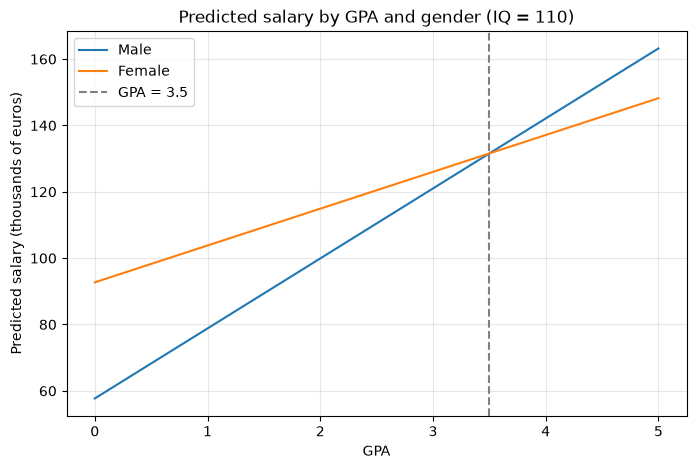

In [3]:
import matplotlib.pyplot as plt

# we plot the difference in the predicted salaries

gpa_values = np.linspace(0, 5, 100)
male_salaries = [predict_salary(gpa, 110, 0) for gpa in gpa_values]
female_salaries = [predict_salary(gpa, 110, 1) for gpa in gpa_values]

plt.figure(figsize=(8, 5))
plt.plot(gpa_values, male_salaries, label="Male")
plt.plot(gpa_values, female_salaries, label="Female")
plt.axvline(x=3.5, linestyle="--", color="gray", label="GPA = 3.5")

plt.xlabel("GPA")
plt.ylabel("Predicted salary (thousands of euros)")
plt.title("Predicted salary by GPA and gender (IQ = 110)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [4]:
# calculate the predicted salary (b)

gpa = 4.0
iq = 110
gender = 1

predicted_salary = predict_salary(gpa, iq, gender)

print(f"Predicted salary: {predicted_salary:.2f} thousand euros")
print(f"Predicted salary: {predicted_salary * 1000:,.2f} euros")

# interaction effect (c)

beta_interaction = 0.01

for gpa, iq in [(2.0, 100), (3.0, 110), (4.0, 130)]:
    effect = beta_interaction * gpa * iq
    print(f"GPA = {gpa}, IQ = {iq}: Interaction term = {effect:.2f}")

Predicted salary: 137.10 thousand euros
Predicted salary: 137,100.00 euros
GPA = 2.0, IQ = 100: Interaction term = 2.00
GPA = 3.0, IQ = 110: Interaction term = 3.30
GPA = 4.0, IQ = 130: Interaction term = 5.20
